# Analyse du scale space — in focus / out of focus

Ce notebook suit les étapes d'analyse de `04_Scale_Space.py` **dans l'ordre**. Chaque étape :
1. **prépare napari** (calques affichés, contraste, outil actif) ;
2. te dit **quoi faire dans napari** et **quelles questions te poser** ;
3. **relit ce que tu as fait dans napari** (lignes tracées, poids) et trace les graphiques correspondants ici.

Le notebook ne donne aucune interprétation : il mesure et affiche, l'analyse reste la tienne.

**Utilisation**
- Lancer depuis le dossier `Optic_Flow` : `jupyter lab 04_Scale_Space_Analysis.ipynb` (venv du projet).
- Exécuter les cellules une par une (Shift + Entrée). Les fenêtres napari restent ouvertes à côté et
  restent utilisables pendant que le notebook tourne.
- Ne ferme pas les fenêtres napari : sinon, relance la cellule **0**.
- La vidéo et la frame se choisissent dans la CONFIG de `04_Scale_Space.py` (`VIDEO`, `VIDEOS[...]["frame"]`).

#### Concepts et transformations
- **Scale space (espace des échelles)**
  - *Simple :* on regarde la même image à plusieurs niveaux de flou, du plus fin au plus grossier, pour voir à quelle taille chaque structure existe.
  - *Théorie / maths :* famille $L(x,y;\sigma) = G_\sigma * I$, avec $G_\sigma$ gaussienne d'écart-type $\sigma$ ; solution de l'équation de la chaleur $\partial_t L = \tfrac12 \nabla^2 L$, $t=\sigma^2$ (Lindeberg). La gaussienne est le seul noyau qui ne crée pas de nouvelles structures en floutant.
- **In focus / out of focus**
  - *Simple :* une cellule dans le plan de mise au point est nette ; hors du plan elle est floue et son contraste change (halo, centre clair).
  - *Théorie / maths :* l'image d'un point = PSF (*point spread function*) du microscope, qui s'élargit avec la défocalisation $\Delta z$. En contraste de phase / fond clair, la défocalisation peut **inverser** le contraste (effet de phase, équation de transport d'intensité $\partial_z I \propto -\nabla\cdot(I\nabla\phi)$).
- **Frame − fond**
  - *Simple :* on retire ce qui ne bouge pas (fond, poussières, éclairage) pour ne garder que les cellules.
  - *Théorie / maths :* $D = I_t - \hat B_t$, $\hat B_t$ moyenne glissante masquée (étape 02), en % de luminosité ; signe : sombre $<0$, clair $>0$.
- **Analyse sans interprétation**
  - *Simple :* le notebook mesure et affiche ; c'est toi qui conclus.
  - *Théorie / maths :* validation qualitative (visuelle) par un expert, référence indépendante du filtre testé.


## 0 — Préparer
Ouvre les deux fenêtres napari (2D : image, bandes, cartes, docks ; 3D : heightmap) et charge les bandes
déjà calculées (ou les calcule).

#### Concepts et transformations
- **Deux vues napari**
  - *Simple :* une fenêtre 2D (images, bandes, cartes) et une fenêtre 3D (relief).
  - *Théorie / maths :* napari = visualiseur multi-calques ; chaque calque = un tableau NumPy + une représentation (Image, Shapes, Points, Surface).
- **Cache des calculs**
  - *Simple :* les bandes et les cartes sont calculées une fois puis relues depuis le disque.
  - *Théorie / maths :* mémoïsation sur fichier ; le nom du fichier contient la vidéo, la frame et l'étendue de la grille σ, donc changer la grille ne relit jamais un ancien résultat.


In [30]:
%gui qt
%matplotlib inline
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt
import napari
import numpy as np
import pandas as pd
from qtpy.QtWidgets import QSlider
from scipy import ndimage

SCRIPT = Path.cwd() / "04_Scale_Space.py"     # the notebook sits next to the script
if not SCRIPT.exists():
    SCRIPT = Path("/Users/juwul/Desktop/Internship/Video_Process_Script/Optic_Flow/04_Scale_Space.py")
spec = importlib.util.spec_from_file_location("scale_space", SCRIPT)
ss = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ss)
h = ss.build_viewers()
viewer, relief, R = h["viewer"], h["relief"], h["results"]
SPAN = 4 * h["noise"]                       # contrast of the images: +- 4 noise std
PREFIX = f"{ss.VIDEO}_4_seg{ss.SEGMENT}_frame{ss.global_frame()}"
CLASSES = {"in_focus": "#2a78d6", "out_of_focus": "#eb6834", "ambigu": "#1baf7a"}
SHORT = {"in_focus": "in", "out_of_focus": "out", "ambigu": "amb"}   # object ids: in0, out3, amb1...
plt.rcParams.update({"figure.dpi": 110, "font.size": 8, "axes.grid": True, "grid.color": "#e4e3dd"})


def shades(cls, n):
    """n colors of the class hue, light to dark (one per object inside a class panel)."""
    from matplotlib.colors import LinearSegmentedColormap
    ramp = LinearSegmentedColormap.from_list(cls, ["#d9d8d2", CLASSES[cls], "#141413"])
    return [ramp(v) for v in np.linspace(0.35, 0.8, n)] if n > 1 else [CLASSES[cls]]


def camera(v):
    """Camera of a viewer (viewer.scene.camera since napari 0.9)."""
    return v.scene.camera if hasattr(v, "scene") else v.camera


def layer(prefix):
    """Layer whose name starts with prefix."""
    return next(l for l in viewer.layers if l.name.startswith(prefix))


def show(*prefixes):
    """Show only the image layers whose name starts with one of the prefixes (shapes / points stay)."""
    for l in viewer.layers:
        if isinstance(l, napari.layers.Image):
            l.visible = any(l.name.startswith(p) for p in prefixes)


def zoom_to(y, x, size=80):
    """Center the 2D viewer on (y, x), about size px wide."""
    camera(viewer).center = (y, x)
    camera(viewer).zoom = 800 / size


def free_path(path):
    """path, or path_2, path_3... : never overwrite."""
    path, k = Path(path), 2
    candidate = path
    while candidate.exists():
        candidate = path.with_name(f"{path.stem}_{k}{path.suffix}")
        k += 1
    return candidate


def band_labels(grid):
    s = GRIDS[grid]
    return [f"{a:.3g}–{b:.3g}" for a, b in zip(s[:-1], s[1:])]


GRIDS = ss.GRIDS
print("frame:", PREFIX, "| grids:", {g: [round(x, 2) for x in s] for g, s in GRIDS.items()})

segment 0, frame 207 (global 207)
  octave: sigmas 1.00, 2.00, 4.00, 8.00, 16.00, 32.00
    loaded: 0003_4_seg0_0-291_frame207_octave_1-32_bands.tif, 0003_4_seg0_0-291_frame207_octave_1-32_maps.tif
  half_octave: sigmas 1.00, 1.41, 2.00, 2.83, 4.00, 5.66, 8.00, 11.31, 16.00, 22.63, 32.00
    loaded: 0003_4_seg0_0-291_frame207_half_octave_1-32_bands.tif, 0003_4_seg0_0-291_frame207_half_octave_1-32_maps.tif
  noise std 0.95 %; reconstruction with all weights 1: max error 2.4e-07 %
  LoG / Hessian loaded: 0003_4_seg0_0-291_frame207_half_octave_1-32_log.tif, 0003_4_seg0_0-291_frame207_half_octave_1-32_hessian_maps.tif, 0003_4_seg0_0-291_frame207_half_octave_1-32_log_blobs.csv
frame: 0003_4_seg0_frame207 | grids: {'octave': [1, 2, 4, 8, 16, 32], 'half_octave': [1.0, 1.41, 2.0, 2.83, 4.0, 5.66, 8.0, 11.31, 16.0, 22.63, 32.0]}


#### Concepts et transformations
- **Chargement du script comme module**
  - *Simple :* le notebook réutilise exactement le code de `04_Scale_Space.py`, sans le recopier.
  - *Théorie / maths :* `importlib.util.spec_from_file_location` → exécution du fichier dans un module `ss` ; une seule source de vérité.
- **SPAN = 4 × bruit**
  - *Simple :* le contraste des images va de −4 à +4 fois le bruit : le fond paraît gris uniforme, les cellules ressortent.
  - *Théorie / maths :* $\hat\sigma_{bruit} = 1{,}4826 \cdot \mathrm{MAD}$, MAD = médiane des $|x - \mathrm{médiane}(x)|$ ; estimateur robuste (insensible aux objets), égal à l'écart-type pour un bruit gaussien.
- **Grille de σ**
  - *Simple :* la liste des tailles de flou testées.
  - *Théorie / maths :* octave : $\sigma_k = 2^k$ (1, 2, …, 32) ; demi-octave : $\sigma_k = 2^{k/2}$ (1, 1,41, …, 32). Rapport constant $r = \sigma_{k+1}/\sigma_k$ = échantillonnage **logarithmique** de l'échelle.
- **Étiquette de bande « a–b »**
  - *Simple :* la bande k contient ce qui se trouve entre le flou σ=a et le flou σ=b.
  - *Théorie / maths :* bande $k$ : intervalle $[\sigma_k, \sigma_{k+1}]$, placée au centre géométrique $\sqrt{\sigma_k\sigma_{k+1}}$.
- **Pas d'écrasement**
  - *Simple :* si un fichier existe déjà, on écrit `_2`, `_3`…
  - *Théorie / maths :* `free_path` : nommage incrémental, préserve les données non suivies par git.


## 1 — L'image d'entrée (frame − fond)
**But :** constituer un échantillon de référence **avant** de regarder les filtres (sinon on valide le filtre
avec le filtre).

**Dans napari** (la cellule ci-dessous prépare tout) :
- seul `2 frame - background` est affiché ;
- trois calques Shapes sont créés, un par classe : `in_focus`, `out_of_focus`, `ambigu` (le nom du calque *est*
  la classe) ;
- sélectionne le calque de la classe, outil **ligne**, et trace une ligne **perpendiculaire** à chaque objet,
  du fond d'un côté au fond de l'autre (toujours la même règle) ;
- coordonnées et valeur sous la souris : barre de statut, avec le calque image sélectionné.

**Questions :** le centre et le bord sont-ils plus sombres ou plus clairs que le fond ? Taille ? Objets
ambigus (raison : intermédiaire, collé, amas, faible, bord de champ, flou de mouvement, autre) ?

#### Concepts et transformations
- **Référence avant filtre**
  - *Simple :* tu classes les objets à l'œil sur l'image brute avant de voir les filtres, pour ne pas être influencé.
  - *Théorie / maths :* vérité terrain indépendante : évite la circularité (valider une méthode avec ses propres sorties) et le biais de confirmation.
- **Ligne perpendiculaire (profil)**
  - *Simple :* une ligne qui traverse l'objet du fond au fond, dans sa largeur.
  - *Théorie / maths :* profil d'intensité $I(s)$ le long d'un segment ; la largeur mesurée = longueur du segment, règle fixe = mesure reproductible.
- **Classe ambiguë**
  - *Simple :* un objet qu'on ne sait pas classer (amas, intermédiaire, flou de mouvement…).
  - *Théorie / maths :* classe de rejet : séparer les cas incertains évite de bruiter les classes de référence.


In [31]:
show("2 frame")
layer("2 frame").contrast_limits = (-SPAN, SPAN)
for name, color in CLASSES.items():
    if name not in viewer.layers:
        shapes = viewer.add_shapes(ndim=2, name=name, face_color="transparent", edge_width=1.5)
        shapes.current_edge_color, shapes.current_face_color, shapes.current_edge_width = color, "transparent", 1.5
viewer.layers.selection.active = viewer.layers["in_focus"]
viewer.layers["in_focus"].mode = "add_line"
print("Trace les lignes dans napari (un calque par classe), puis exécute la cellule suivante.")

Trace les lignes dans napari (un calque par classe), puis exécute la cellule suivante.


#### Concepts et transformations
- **Calque Shapes par classe**
  - *Simple :* le nom du calque est la classe : tout ce que tu traces dans `in_focus` est in focus.
  - *Théorie / maths :* annotation vectorielle (segments en coordonnées image (y, x)), une étiquette par calque.
- **Contraste symétrique**
  - *Simple :* 0 (le fond) est au milieu du gris ; plus sombre = noir, plus clair = blanc.
  - *Théorie / maths :* *contrast limits* $[-S, +S]$ : application linéaire $v \mapsto (v+S)/2S$ écrêtée à $[0,1]$.


**Relire les lignes tracées.** À relancer chaque fois que tu ajoutes ou modifies des lignes : toutes les
cellules suivantes utilisent ce tableau `objects` (centre = milieu de la ligne, largeur = longueur de la ligne).
Les centres sont aussi ajoutés dans napari (calque `object centres`, avec l'identifiant de chaque objet).

#### Concepts et transformations
- **Centre et largeur d'un objet**
  - *Simple :* centre = milieu de la ligne ; largeur = longueur de la ligne.
  - *Théorie / maths :* centre $= (p_1 + p_2)/2$ ; largeur $= \sum_i \|p_{i+1} - p_i\|$ (longueur de la polyligne).


In [32]:
def read_objects():
    rows = []
    for name in CLASSES:
        if name not in viewer.layers:
            continue
        for i, s in enumerate(viewer.layers[name].data):
            yx = np.asarray(s)[:, -2:]
            if len(yx) < 2:
                continue
            (y1, x1), (y2, x2) = yx[0], yx[-1]
            width = float(np.linalg.norm(np.diff(yx, axis=0), axis=1).sum())
            rows.append(dict(cls=name, id=f"{SHORT[name]}{i}", y=(y1 + y2) / 2, x=(x1 + x2) / 2,
                             y1=y1, x1=x1, y2=y2, x2=x2, width=width))
    return pd.DataFrame(rows, columns=["cls", "id", "y", "x", "y1", "x1", "y2", "x2", "width"])


def mark_centres(objects):
    features = pd.DataFrame({"id": objects["id"], "cls": objects["cls"]})
    data = objects[["y", "x"]].to_numpy()
    colors = [CLASSES[c] for c in objects["cls"]] or "white"
    if "object centres" in viewer.layers:
        viewer.layers.remove("object centres")
    viewer.add_points(data, name="object centres", size=4, face_color=colors, border_color="white",
                      features=features, text={"string": "{id}", "color": "white", "size": 9,
                                               "anchor": "upper_left"})


objects = read_objects()
mark_centres(objects)
print(objects.groupby("cls").size().to_string() if len(objects) else "aucune ligne tracée")
objects.round(1)

aucune ligne tracée


,cls,id,y,x,y1,x1,y2,x2,width


#### Concepts et transformations
- **Tableau `objects`**
  - *Simple :* une ligne par objet : classe, identifiant, centre, extrémités, largeur.
  - *Théorie / maths :* DataFrame pandas = table relationnelle ; toutes les étapes suivantes lisent cette table (une seule source).
- **Calque Points avec texte**
  - *Simple :* un point coloré au centre de chaque objet, avec son nom (in0, out3…).
  - *Théorie / maths :* calque Points + `features` (attributs par point) + `text` (étiquette formatée depuis les attributs).


**Enregistrer / recharger les lignes** (CSV sur le disque externe, jamais écrasé : `_2`, `_3`... si le fichier
existe) : décommente `save_objects(objects)`. Pour reprendre une autre fois : relancer la cellule 0, puis
`load_objects(<chemin>)` et « Relire les lignes tracées ».

#### Concepts et transformations
- **Persistance**
  - *Simple :* on enregistre les lignes pour les retrouver après fermeture.
  - *Théorie / maths :* sérialisation CSV des coordonnées ; rechargement = reconstruction des Shapes depuis la table.


In [33]:
def save_objects(objects):
    path = free_path(ss.DATA_DIR / f"{PREFIX}_objects.csv")
    objects.to_csv(path, index=False)
    print("enregistré :", path)


def load_objects(path):
    """Put the lines of a saved CSV back into the class layers."""
    saved = pd.read_csv(path)
    for name, color in CLASSES.items():
        lines = [np.array([[o.y1, o.x1], [o.y2, o.x2]]) for o in saved[saved["cls"] == name].itertuples()]
        if name not in viewer.layers:
            viewer.add_shapes(ndim=2, name=name, face_color="transparent")
        if lines:
            viewer.layers[name].add_lines(lines, edge_color=color, edge_width=1.5)
    print(f"{len(saved)} lignes rechargées : relance « Relire les lignes tracées »")


# save_objects(objects)
# load_objects("/Volumes/Extreme SSD/TIFFIle/Optic_Flow/<nom>_objects.csv")

#### Concepts et transformations
- **Sauvegarde / rechargement**
  - *Simple :* `save_objects` écrit le CSV, `load_objects` remet les lignes dans napari.
  - *Théorie / maths :* aller-retour table ↔ calques ; le nom libre (`free_path`) garantit qu'aucune annotation n'est perdue.


## 2 — Les bandes (le filtre lui-même)
**Ce que c'est :** chaque bande B_k = G_σk − G_σk+1 ne garde que les structures de taille comprise entre deux σ
consécutifs. Le curseur du calque fait défiler les bandes, de la plus fine (0) à la plus grossière.

**Dans napari :** seul le calque des bandes est affiché, contraste **fixe et symétrique** autour de 0. Fais
défiler le curseur en regardant un même objet (`zoom_to(y, x)` centre la vue sur un objet).

**Questions :** à quelle bande l'objet est-il le plus contrasté ? À quelles bandes disparaît-il ? Le signe
(noir / blanc) au même endroit change-t-il d'une bande à l'autre ? Que reste-t-il du fond dans chaque bande ?
Comparer ensuite avec `BAND_GRID = "octave"`.

**Graphique ci-dessous :** une ligne par objet, une colonne par bande, même contraste partout
(`same_scale=False` : contraste propre à chaque bande, pour voir aussi les bandes faibles).

#### Concepts et transformations
- **Flou gaussien masqué**
  - *Simple :* on floute l'image en n'utilisant que les pixels qui ont des données (le bord noir de la stabilisation n'entre pas).
  - *Théorie / maths :* convolution normalisée : $G_\sigma[I] = \dfrac{G_\sigma * (I\cdot M)}{G_\sigma * M}$, $M$ = masque des pixels valides.
- **Bande B_k (DoG)**
  - *Simple :* différence de deux flous successifs : il ne reste que les structures de taille entre σ_k et σ_k+1.
  - *Théorie / maths :* $B_k = \dfrac{G_{\sigma_k} - G_{\sigma_{k+1}}}{r-1}$ ; *Difference of Gaussians*, filtre **passe-bande** spatial ; $G_{\sigma} - G_{r\sigma} \approx -(r-1)\,\sigma^2\nabla^2 G_\sigma$ (Laplacien de gaussienne normalisé) ; la division par $(r-1)$ met octave et demi-octave sur la même échelle.
- **Signe de B**
  - *Simple :* B < 0 : le pixel est plus sombre que son voisinage à cette taille ; B > 0 : plus clair.
  - *Théorie / maths :* $B \propto -\sigma^2\nabla^2 L$ : signe opposé à la courbure (le Laplacien est positif au fond d'une cuvette sombre, d'où $B<0$).
- **Pyramide laplacienne**
  - *Simple :* les bandes empilées + le reste grossier redonnent l'image exacte.
  - *Théorie / maths :* somme télescopique : $I = (I - G_{\sigma_0}) + \sum_k (G_{\sigma_k} - G_{\sigma_{k+1}}) + G_{\sigma_K}$ (reconstruction exacte, base du sharpening).


In [34]:
BAND_GRID = "half_octave"            # or "octave"
show(f"4 bands {BAND_GRID}")
layer(f"4 bands {BAND_GRID}").contrast_limits = (-SPAN, SPAN)
viewer.dims.set_current_step(0, 0)
print("bandes :", dict(enumerate(band_labels(BAND_GRID))))
# zoom_to(y, x, size=80)

bandes : {0: '1–1.41', 1: '1.41–2', 2: '2–2.83', 3: '2.83–4', 4: '4–5.66', 5: '5.66–8', 6: '8–11.3', 7: '11.3–16', 8: '16–22.6', 9: '22.6–32'}


#### Concepts et transformations
- **Curseur de bande**
  - *Simple :* le curseur de napari fait défiler les bandes, 0 = la plus fine.
  - *Théorie / maths :* pile 3D (bande, y, x) ; le curseur choisit l'indice sur la première dimension (`dims.set_current_step`).
- **Contraste fixe**
  - *Simple :* même échelle de gris pour toutes les bandes, pour comparer les amplitudes entre elles.
  - *Théorie / maths :* limites $\pm 4\hat\sigma_{bruit}$ identiques : visualisation à échelle absolue (pas de renormalisation par bande).


In [35]:
def band_gallery(grid=BAND_GRID, per_class=4, same_scale=True):
    bands = R[grid]["bands"]
    labels = band_labels(grid)
    sel = objects.groupby("cls", sort=False).head(per_class)
    if sel.empty:
        return print("aucun objet : trace des lignes à l'étape 1")
    limits = [SPAN] * len(bands) if same_scale else [float(np.percentile(np.abs(b), 99.5)) for b in bands]
    fig, axes = plt.subplots(len(sel), len(bands), figsize=(1.1 * len(bands), 1.2 * len(sel)), squeeze=False)
    for row, o in enumerate(sel.itertuples()):
        half = int(max(12, 1.5 * o.width))
        yc, xc = int(round(o.y)), int(round(o.x))
        for k, band in enumerate(bands):
            ax = axes[row, k]
            ax.imshow(band[max(0, yc - half):yc + half + 1, max(0, xc - half):xc + half + 1], cmap="gray",
                      vmin=-limits[k], vmax=limits[k])
            ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
            if row == 0:
                ax.set_title(labels[k], fontsize=7)
        axes[row, 0].set_ylabel(o.id, color=CLASSES[o.cls], fontsize=8, rotation=0, ha="right", va="center")
    fig.suptitle(f"Bandes {grid} (σ en px) — noir < 0 < blanc", fontsize=9)
    plt.show()


band_gallery()

aucun objet : trace des lignes à l'étape 1


#### Concepts et transformations
- **Galerie de vignettes**
  - *Simple :* pour chaque objet, un petit carré découpé dans chaque bande.
  - *Théorie / maths :* recadrage (ROI) de demi-côté $\max(12, 1{,}5\,w)$ autour du centre ; matrice objets × bandes (*small multiples*).
- **Même échelle / échelle propre**
  - *Simple :* `same_scale=True` compare les bandes entre elles ; `False` montre aussi les bandes faibles.
  - *Théorie / maths :* échelle propre = limites au percentile 99,5 de $|B_k|$ de chaque bande (normalisation par quantile).


## 3 — Les courbes B(σ) (le graphique central)
**Ce que c'est :** pour un pixel, la valeur de chaque bande en fonction de σ (axe x logarithmique ; y < 0 =
plus sombre que l'entourage à cette échelle, y > 0 = plus clair). Trait plein et ronds = demi-octave ; carrés
= octave.

**Dans napari :** le dock *B(sigma) curves* reste utilisable (Shift + clic sur un pixel).

**Graphiques ci-dessous**, une colonne par classe :
- ligne 1 : courbe au **centre** de chaque objet ;
- ligne 2 : courbe **moyenne le long de la ligne** tracée (signature de l'objet entier) ;
- les courbes du **fond** (pixels tirés au hasard hors des objets) en gris, comme référence du bruit.

**Lire chaque courbe :** 1. signe dominant · 2. position de l'extremum (σ caractéristique) · 3. amplitude ·
4. forme (cloche, pente, plateau) · 5. passage par 0 et à quel σ. Un extremum **au bord** du graphe = vrai pic
peut-être hors de la grille.

Le tableau donne, au centre de chaque objet : σ du pic (interpolé), amplitude, σ du changement de signe,
significativité, et si l'extremum est sur la première / dernière bande.

#### Concepts et transformations
- **Courbe B(σ)**
  - *Simple :* pour un pixel, la valeur de chaque bande en fonction de la taille : sa signature d'échelle.
  - *Théorie / maths :* réponse $B(x_0, \sigma)$ du pixel $x_0$ à travers l'espace des échelles ; axe $\sigma$ logarithmique car la grille l'est.
- **Échelle caractéristique**
  - *Simple :* la taille où la réponse est la plus forte = la taille de la structure autour du pixel.
  - *Théorie / maths :* $\sigma^* = \arg\max_\sigma |B(x_0,\sigma)|$ ; sélection automatique d'échelle (Lindeberg), possible grâce à la normalisation $\sigma^2\nabla^2$.
- **Courbes du fond**
  - *Simple :* des pixels sans objet tracés en gris : à quoi ressemble le bruit.
  - *Théorie / maths :* distribution de référence (hypothèse nulle) : une courbe d'objet qui reste dans le faisceau gris n'est pas distinguable du bruit.
- **Extremum en bord de grille**
  - *Simple :* si le maximum est sur la première ou la dernière bande, le vrai pic est peut-être en dehors.
  - *Théorie / maths :* maximum de bord : censure de la mesure (on sait seulement « ≤ σ_min » ou « ≥ σ_max »).


In [36]:
def line_points(o, step=0.5):
    n = max(2, int(np.ceil(o.width / step)) + 1)
    return np.linspace(o.y1, o.y2, n), np.linspace(o.x1, o.x2, n)


def sample(image, ys, xs, order=1):
    return ndimage.map_coordinates(image, [ys, xs], order=order, mode="nearest")


def center_curve(grid, o):
    return R[grid]["bands"][:, int(round(o.y)), int(round(o.x))]


def line_curve(grid, o):
    ys, xs = line_points(o)
    return np.array([sample(b, ys, xs).mean() for b in R[grid]["bands"]])


def background_pixels(n=20, seed=0):
    """Random pixels that are not significant in the half-octave maps (the noise reference)."""
    rng = np.random.default_rng(seed)
    noise = ~np.isfinite(R["half_octave"]["maps"]["sigma_peak_interp"]) & h["valid"]
    yy, xx = np.nonzero(noise)
    pick = rng.choice(len(yy), size=n, replace=False)
    return yy[pick], xx[pick]


def plot_curves():
    present = [c for c in CLASSES if (objects["cls"] == c).any()]
    if not present:
        return print("aucun objet : trace des lignes à l'étape 1")
    by, bx = background_pixels()
    fig, axes = plt.subplots(2, len(present), figsize=(4.2 * len(present), 6), squeeze=False, sharey="row")
    for col, cls in enumerate(present):
        for row, (curve, title) in enumerate([(center_curve, "centre"), (line_curve, "moyenne le long de la ligne")]):
            ax = axes[row, col]
            for y, x in zip(by, bx):
                ax.plot(R["half_octave"]["centers"], R["half_octave"]["bands"][:, y, x], color="#c9c8c2", lw=0.6)
            group = objects[objects["cls"] == cls]
            for o, color in zip(group.itertuples(), shades(cls, len(group))):
                ax.plot(R["half_octave"]["centers"], curve("half_octave", o), "-o", ms=3, lw=1.4, color=color)
                ax.plot(R["octave"]["centers"], curve("octave", o), "s", ms=5, mfc="none", color=color)
                ax.annotate(o.id, (R["half_octave"]["centers"][0], curve("half_octave", o)[0]), fontsize=7,
                            xytext=(-16, 0), textcoords="offset points", va="center")
            ax.axhline(0, color="#5f5e58", lw=0.8)
            ax.set_xscale("log")
            ax.set_xticks(GRIDS["octave"], [f"{s:g}" for s in GRIDS["octave"]])
            ax.minorticks_off()
            ax.set_title(f"{cls} — {title}", color=CLASSES[cls], loc="left")
            ax.set_xlabel("σ de la bande (px)")
        axes[0, 0].set_ylabel("B / (r − 1)  (%)")
        axes[1, 0].set_ylabel("B / (r − 1)  (%)")
    fig.tight_layout()
    plt.show()


def center_features(grid="half_octave"):
    maps, K = R[grid]["maps"], len(R[grid]["bands"])
    rows = []
    for o in objects.itertuples():
        y, x = int(round(o.y)), int(round(o.x))
        k = int(np.argmax(np.abs(center_curve(grid, o))))
        rows.append(dict(cls=o.cls, id=o.id, width=round(o.width, 1), expected_sigma=round(o.width / 2 ** 1.5, 2),
                         sigma_peak=maps["sigma_peak_interp"][y, x], amplitude=maps["amplitude"][y, x],
                         sigma_sign_change=maps["sigma_sign_change"][y, x],
                         significance=maps["significance"][y, x],
                         peak_on_grid_edge={0: "first", K - 1: "last"}.get(k, "")))
    columns = ["cls", "id", "width", "expected_sigma", "sigma_peak", "amplitude", "sigma_sign_change",
               "significance", "peak_on_grid_edge"]
    return pd.DataFrame(rows, columns=columns).round(2)


plot_curves()
center_features()

aucun objet : trace des lignes à l'étape 1


,cls,id,width,expected_sigma,sigma_peak,amplitude,sigma_sign_change,significance,peak_on_grid_edge


#### Concepts et transformations
- **Échantillonnage le long de la ligne**
  - *Simple :* on lit l'image tous les 0,5 px le long de la ligne tracée.
  - *Théorie / maths :* interpolation **bilinéaire** (`map_coordinates`, ordre 1) en coordonnées sous-pixel.
- **Courbe au centre / moyenne le long de la ligne**
  - *Simple :* le centre seul, ou la moyenne de tout le profil (signature de l'objet entier).
  - *Théorie / maths :* $\bar B_k = \frac{1}{N}\sum_{i} B_k(p_i)$ sur les points $p_i$ du segment ; moyenne = réduction du bruit en $1/\sqrt N$ mais mélange centre et bord.
- **Pixels de fond tirés au hasard**
  - *Simple :* 20 pixels non significatifs, tirés avec une graine fixe (toujours les mêmes).
  - *Théorie / maths :* échantillonnage aléatoire sans remise, reproductible (`default_rng(seed=0)`).
- **Tableau au centre**
  - *Simple :* σ du pic, amplitude, σ du changement de signe, significativité, pic en bord de grille.
  - *Théorie / maths :* lecture des cartes (étape 4) au pixel central de chaque objet.


`expected_sigma` = largeur / 2√2 : le σ où un objet de cette largeur répond le plus (valeur théorique, pour
comparer avec `sigma_peak`). Valeurs vides (NaN) = non significatif au centre.

#### Concepts et transformations
- **σ attendu = largeur / 2√2**
  - *Simple :* la taille de flou à laquelle un objet de largeur w doit répondre le plus fort.
  - *Théorie / maths :* pour un disque de rayon $\rho$, la réponse normalisée $\sigma^2\nabla^2 G_\sigma$ au centre est maximale pour $\sigma = \rho/\sqrt2$, soit $\sigma = w/(2\sqrt2)$ avec $w = 2\rho$.
- **NaN**
  - *Simple :* case vide = pas assez de signal au centre pour donner une mesure.
  - *Théorie / maths :* valeur manquante quand la significativité $< K = 3$.


## 4 — Les cartes (résumé de chaque courbe en un nombre)
| Calque | Ce qu'il représente |
|---|---|
| `4 sigma peak` (log2 : 0 = 1 px … 5 = 32 px ; noir = non significatif) | σ de l'extremum de \|B\|, interpolé |
| `4 amplitude at peak` (bleu < 0, rouge > 0) | valeur signée de B à l'extremum |
| `4 sigma of sign change` | σ du premier passage par 0 (les deux côtés significatifs) |

**Dans napari :** la cellule superpose une carte à l'image d'entrée (opacité réglable). Change `MAP` pour
passer d'une carte à l'autre.

**Questions :** couleur homogène dans une classe ? différente entre classes ? uniforme sur un objet ou
variable du centre au bord ? fond bien noir ? La couleur au pixel cliqué correspond-elle à l'extremum de sa
courbe ?

**Graphique ci-dessous :** les cartes **le long de chaque ligne tracée** (position −1 = une extrémité, 0 = centre,
+1 = autre extrémité), une colonne par classe.

#### Concepts et transformations
- **Carte**
  - *Simple :* une image où chaque pixel porte un seul nombre qui résume sa courbe B(σ).
  - *Théorie / maths :* réduction de la dimension « échelle » : $\mathbb{R}^{K} \to \mathbb{R}$ par pixel (argmax, valeur au max, passage par zéro).
- **σ du pic (interpolé)**
  - *Simple :* la taille de la structure, affinée entre deux bandes.
  - *Théorie / maths :* interpolation **parabolique** sur $\log_2\sigma$ avec $a, b, c = |B|$ aux bandes $k-1, k, k+1$ : décalage $\delta = \dfrac{a - c}{2(a - 2b + c)}$, borné à $\pm\frac12$ ; $\sigma^* = 2^{\log_2\sigma_k + \delta\,\log_2 r}$.
- **Amplitude au pic**
  - *Simple :* la valeur de B au pic, avec son signe : sombre (bleu) ou clair (rouge), et de combien.
  - *Théorie / maths :* $A = B_{k^*}(x)$ en % ; carte divergente centrée sur 0.
- **σ du changement de signe**
  - *Simple :* la première taille où B passe du clair au sombre (ou l'inverse).
  - *Théorie / maths :* passage par zéro de $B(\sigma)$, localisé par interpolation linéaire $t = \frac{B_k}{B_k - B_{k+1}}$, retenu seulement si une bande significative existe de chaque côté.
- **Significativité**
  - *Simple :* combien de fois le pic dépasse le bruit de sa bande.
  - *Théorie / maths :* $Z = |A| / \hat\sigma_{bruit,k^*}$ (rapport signal/bruit, score z) ; pixel gardé si $Z \ge 3$, sinon noir (le bruit a aussi un pic, à une échelle aléatoire).
- **Affichage en log₂ σ**
  - *Simple :* 0 = 1 px, 1 = 2 px, … 5 = 32 px ; noir = non significatif.
  - *Théorie / maths :* carte de couleurs *turbo* sur $[0, \log_2 \sigma_{max}]$ ; une unité = un doublement de taille.


In [37]:
MAP_GRID = "half_octave"
MAP = "4 sigma peak"                 # "4 amplitude at peak" or "4 sigma of sign change"
show("2 frame", f"{MAP} {MAP_GRID}")
layer(f"{MAP} {MAP_GRID}").opacity = 0.5

#### Concepts et transformations
- **Superposition**
  - *Simple :* la carte est posée sur l'image d'entrée à demi-transparence.
  - *Théorie / maths :* mélange alpha : $C = \alpha\,C_{carte} + (1-\alpha)\,C_{image}$, $\alpha$ = opacité (0,5).


In [38]:
def plot_map_profiles(grid=MAP_GRID):
    present = [c for c in CLASSES if (objects["cls"] == c).any()]
    if not present:
        return print("aucun objet : trace des lignes à l'étape 1")
    maps = R[grid]["maps"]
    rows = [("sigma_peak_interp", "σ du pic (px)", True), ("amplitude", "amplitude au pic (%)", False),
            ("sigma_sign_change", "σ du changement de signe (px)", True)]
    fig, axes = plt.subplots(len(rows), len(present), figsize=(4.2 * len(present), 7.5), squeeze=False,
                             sharey="row")
    for col, cls in enumerate(present):
        group = objects[objects["cls"] == cls]
        for o, color in zip(group.itertuples(), shades(cls, len(group))):
            ys, xs = line_points(o)
            pos = np.linspace(-1, 1, len(ys))
            for row, (key, label, log) in enumerate(rows):
                values = sample(maps[key], ys, xs, order=0)
                axes[row, col].plot(pos, values, "-", lw=1.2, marker=".", ms=3, label=o.id, color=color)
        for row, (key, label, log) in enumerate(rows):
            ax = axes[row, col]
            if log:
                ax.set_yscale("log", base=2)
                ax.set_yticks(GRIDS["octave"], [f"{s:g}" for s in GRIDS["octave"]])
                ax.minorticks_off()
            else:
                ax.axhline(0, color="#5f5e58", lw=0.8)
            ax.set_ylabel(label)
        axes[0, col].set_title(cls, color=CLASSES[cls], loc="left")
        axes[0, col].legend(fontsize=6, ncol=2)
        axes[-1, col].set_xlabel("position le long de la ligne (−1 … centre 0 … +1)")
        axes[-1, col].set_xlim(-1.05, 1.05)
    fig.tight_layout()
    plt.show()


plot_map_profiles()

aucun objet : trace des lignes à l'étape 1


#### Concepts et transformations
- **Profil des cartes le long de la ligne**
  - *Simple :* comment σ, amplitude et changement de signe varient du bord au centre puis à l'autre bord.
  - *Théorie / maths :* position normalisée $s \in [-1, 1]$ (0 = centre) : compare des objets de tailles différentes sur le même axe.
- **Plus proche voisin**
  - *Simple :* on lit la valeur du pixel le plus proche sans mélanger les voisins.
  - *Théorie / maths :* interpolation d'ordre 0 : nécessaire car les cartes contiennent des NaN et des valeurs de bande discrètes (une moyenne n'aurait pas de sens).
- **Axe log₂**
  - *Simple :* chaque graduation double la taille.
  - *Théorie / maths :* échelle logarithmique base 2, cohérente avec la grille.


## 5 — Les histogrammes
**Ce que c'est :** distribution du σ du pic sur **tous les pixels significatifs**, pixels à pic sombre (B < 0) et
à pic clair (B > 0) séparés. Les traits verticaux en bas = σ du pic au centre de tes objets, couleur de la classe.

**Questions :** une ou plusieurs bosses ? Distributions sombre / claire décalées ou superposées ? Accumulation
sur la première / dernière classe (grille trop courte) ? Où tombent tes objets ? (noir plein = pic sombre, gris
tirets = pic clair ; traits de couleur = tes objets.)

**Limite :** on compte des pixels, pas des objets (les gros objets pèsent plus, un objet contribue à plusieurs σ).
Les pics isolés tout à gauche / tout à droite = extremums sur la première / dernière bande (pas d'interpolation
possible).

#### Concepts et transformations
- **Histogramme**
  - *Simple :* combien de pixels ont leur pic à chaque σ.
  - *Théorie / maths :* estimation de la densité $p(\sigma^*)$ sur les pixels significatifs ; plusieurs bosses = mélange de populations (distribution **multimodale**).
- **Séparé par signe**
  - *Simple :* pics sombres et pics clairs comptés à part.
  - *Théorie / maths :* densités conditionnelles $p(\sigma^* \mid A<0)$ et $p(\sigma^* \mid A>0)$.
- **Pixels, pas objets**
  - *Simple :* un gros objet a plus de pixels, il pèse plus.
  - *Théorie / maths :* pondération par l'aire : l'histogramme est biaisé vers les grandes structures (biais d'échantillonnage).


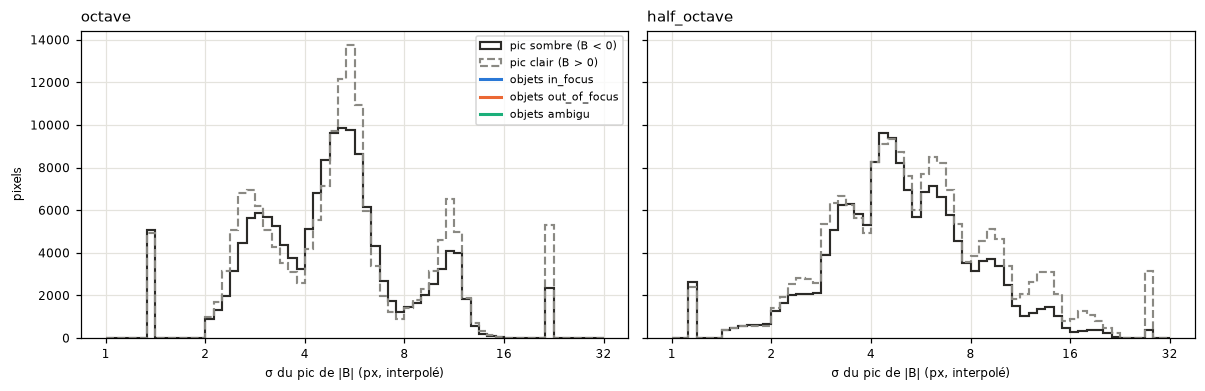

In [39]:
def plot_histograms():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    bins = np.geomspace(1, 2 ** ss.LOG_MAX, 61)
    for ax, grid in zip(axes, GRIDS):
        maps = R[grid]["maps"]
        sigma, amp = maps["sigma_peak_interp"], maps["amplitude"]
        for sign, color, style, label in ((-1, "#2b2a27", "-", "pic sombre (B < 0)"),
                                          (1, "#8a8983", "--", "pic clair (B > 0)")):
            sel = np.isfinite(sigma) & (np.sign(amp) == sign)
            ax.hist(sigma[sel], bins=bins, histtype="step", lw=1.4, color=color, linestyle=style, label=label)
        top = ax.get_ylim()[1]
        for o in objects.itertuples():
            s = maps["sigma_peak_interp"][int(round(o.y)), int(round(o.x))]
            if np.isfinite(s):
                ax.plot([s, s], [0, 0.08 * top], color=CLASSES[o.cls], lw=2)
        ax.set_xscale("log")
        ax.set_xticks(GRIDS["octave"], [f"{s:g}" for s in GRIDS["octave"]])
        ax.minorticks_off()
        ax.set_title(grid, loc="left")
        ax.set_xlabel("σ du pic de |B| (px, interpolé)")
    axes[0].set_ylabel("pixels")
    handles = axes[0].get_legend_handles_labels()[0] + [plt.Line2D([], [], color=c, lw=2) for c in CLASSES.values()]
    axes[0].legend(handles, ["pic sombre (B < 0)", "pic clair (B > 0)"] + [f"objets {c}" for c in CLASSES],
                   fontsize=7)
    fig.tight_layout()
    plt.show()


plot_histograms()

#### Concepts et transformations
- **Classes logarithmiques**
  - *Simple :* les intervalles de l'histogramme ont tous la même largeur sur l'axe log.
  - *Théorie / maths :* `geomspace` : bornes en progression géométrique, uniformes en $\log\sigma$.
- **Traits des objets**
  - *Simple :* la position de tes objets dans la distribution de tous les pixels.
  - *Théorie / maths :* repères (*rug*) : situe l'échantillon annoté dans la population.


## 6 — Comparer octave et demi-octave
**Dans napari :** la cellule affiche `4 sigma peak octave` ; relance-la avec `"half_octave"` pour comparer sur
la même zone.

**Graphique :** σ du pic au centre de chaque objet, octave (y) contre demi-octave (x) ; sur la diagonale = les deux
grilles donnent la même échelle.

**Questions :** les deux grilles classent-elles les mêmes objets de la même façon ? La demi-octave apporte-t-elle
une distinction que l'octave n'a pas ? **Critère :** la grille la plus simple qui conserve les distinctions vues aux
étapes 3 à 5.

#### Concepts et transformations
- **Octave vs demi-octave**
  - *Simple :* l'octave teste 6 tailles, la demi-octave 11 : plus fin, mais plus de calcul et de bruit.
  - *Théorie / maths :* résolution d'échelle $\log_2 r = 1$ ou $\tfrac12$ ; bandes plus étroites = meilleure localisation de $\sigma^*$, mais bandes plus redondantes (fortement corrélées).
- **Critère de parcimonie**
  - *Simple :* on garde la grille la plus simple qui conserve les mêmes distinctions.
  - *Théorie / maths :* rasoir d'Ockham : à pouvoir de séparation égal, le modèle avec le moins de paramètres.


aucun objet : trace ou recharge les lignes (étape 1)


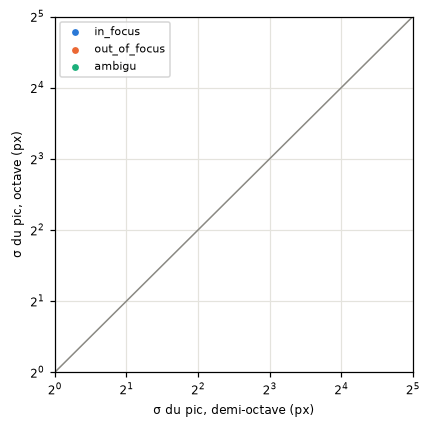

,cls,id,sigma_peak_half_octave,sigma_peak_octave,log2_ratio


In [40]:
COMPARE = "octave"                   # then "half_octave"
show("2 frame", f"4 sigma peak {COMPARE}")
layer(f"4 sigma peak {COMPARE}").opacity = 0.5

if objects.empty:
    print("aucun objet : trace ou recharge les lignes (étape 1)")
both = center_features("half_octave")[["cls", "id", "sigma_peak"]].merge(
    center_features("octave")[["id", "sigma_peak"]], on="id", suffixes=("_half_octave", "_octave"))
both["log2_ratio"] = np.log2(both["sigma_peak_octave"] / both["sigma_peak_half_octave"]).round(2)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
lim = (1, 2 ** ss.LOG_MAX)
ax.plot(lim, lim, color="#8a8983", lw=1)
for cls, color in CLASSES.items():
    sel = both[both["cls"] == cls]
    ax.scatter(sel["sigma_peak_half_octave"], sel["sigma_peak_octave"], color=color, s=30, label=cls,
               edgecolor="white")
    for o in sel.itertuples():
        ax.annotate(o.id, (o.sigma_peak_half_octave, o.sigma_peak_octave), fontsize=7, xytext=(3, 3),
                    textcoords="offset points")
ax.set_xscale("log", base=2), ax.set_yscale("log", base=2), ax.set_xlim(lim), ax.set_ylim(lim)
ax.set_xlabel("σ du pic, demi-octave (px)"), ax.set_ylabel("σ du pic, octave (px)")
ax.legend(fontsize=7)
plt.show()
both

#### Concepts et transformations
- **Nuage octave contre demi-octave**
  - *Simple :* chaque point = un objet ; sur la diagonale, les deux grilles sont d'accord.
  - *Théorie / maths :* diagramme de concordance, droite $y = x$ ; écart mesuré par $\log_2(\sigma^*_{oct}/\sigma^*_{demi})$ (0 = accord, ±1 = facteur 2).


## 7 — Le sharpening (poids des bandes)
**Ce que c'est :** I' = w0·(fin) + Σ w_k·B_k + (reste grossier). Poids 1 = bande inchangée (tous à 1 = image
d'origine) ; > 1 amplifie ; < 1 atténue ; 0 supprime.

**Dans napari :** le dock *sharpening weights* et cette cellule pilotent les **mêmes** curseurs :
`set_weights({index: poids})` (les index sont listés ci-dessous), ou bouge les curseurs à la main puis relance
la cellule de mesure. `4 sharpened` s'affiche dès que les poids changent, la heightmap suit.

**Méthode :** bouger une bande à la fois ; partir des bandes où les courbes des classes diffèrent (étape 3).

**Questions :** l'écart visuel entre classes augmente-t-il ? Le fond reste-t-il propre (les bandes fines
amplifient le bruit) ? Artefacts (anneaux / oscillations autour des objets, bords dédoublés) ?

**Mesures ci-dessous :** profils le long de chaque ligne (originale en gris, sharpenée en couleur), et tableau du
contraste de chaque objet = valeur au centre − moyenne des deux extrémités de la ligne, avant / après. Chaque jeu
de poids mesuré est gardé dans `history`.

#### Concepts et transformations
- **Sharpening par poids de bandes**
  - *Simple :* on renforce ou on atténue certaines tailles de détails, puis on recompose l'image.
  - *Théorie / maths :* $I' = w_0\,(I - G_{\sigma_0}) + \sum_k w_k\,(G_{\sigma_k} - G_{\sigma_{k+1}}) + G_{\sigma_K}$ ; tous les $w=1$ ⇒ $I' = I$ (pyramide laplacienne). Égaliseur graphique en fréquences spatiales ; généralise le masque flou (*unsharp masking*).
- **Amplification du bruit**
  - *Simple :* renforcer les bandes fines renforce aussi le bruit.
  - *Théorie / maths :* le bruit blanc a de l'énergie à toutes les fréquences ; un gain $w$ multiplie son écart-type dans la bande par $w$.
- **Anneaux (artefacts)**
  - *Simple :* renforcer une seule bande crée des cercles clairs/sombres autour des objets.
  - *Théorie / maths :* un filtre passe-bande a un noyau oscillant (« chapeau mexicain ») : réponse impulsionnelle avec lobes négatifs (*ringing*).


In [41]:
panel = h["weights_panel"]
print(pd.Series(panel.names, name="composante").to_string())


def current_weights():
    return np.array([s.value() / 10 for s in panel.findChildren(QSlider)])


def set_weights(changes=None, reset=True):
    """changes = {index: weight}; reset=True starts from all 1."""
    w = np.ones(len(panel.names)) if reset else current_weights()
    for k, v in (changes or {}).items():
        w[k] = v
    panel.set_weights(w)
    return current_weights()


history = []
set_weights({})                      # example: set_weights({0: 0.5, 6: 2.0, 7: 2.0})

0       fine (< 1 px)
1      band 1-1.41 px
2      band 1.41-2 px
3      band 2-2.83 px
4      band 2.83-4 px
5      band 4-5.66 px
6      band 5.66-8 px
7      band 8-11.3 px
8     band 11.3-16 px
9     band 16-22.6 px
10    band 22.6-32 px


  weights: 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0


array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

#### Concepts et transformations
- **Vecteur de poids**
  - *Simple :* une liste de nombres : le premier pour le détail le plus fin, puis un par bande demi-octave.
  - *Théorie / maths :* $w = (w_0, w_1, \dots, w_K)$ ; le curseur stocke $10\,w$ (entier), d'où la division par 10 ; le reste grossier $G_{\sigma_K}$ garde un poids fixe 1.
- **`set_weights`**
  - *Simple :* change les curseurs depuis le notebook ; napari se met à jour.
  - *Théorie / maths :* les curseurs et le notebook partagent le même état (une seule mise à jour, signaux Qt bloqués pendant l'écriture).


In [42]:
def measure_sharpening():
    present = [c for c in CLASSES if (objects["cls"] == c).any()]
    if not present:
        return print("aucun objet : trace des lignes à l'étape 1")
    original, sharp, w = h["diff"], h["sharp"].data, current_weights()
    fig, axes = plt.subplots(1, len(present), figsize=(4.2 * len(present), 3.4), squeeze=False, sharey=True)
    rows = []
    for col, cls in enumerate(present):
        ax = axes[0, col]
        group = objects[objects["cls"] == cls]
        for o, color in zip(group.itertuples(), shades(cls, len(group))):
            ys, xs = line_points(o)
            pos = np.linspace(-1, 1, len(ys))
            before, after = sample(original, ys, xs), sample(sharp, ys, xs)
            ax.plot(pos, before, color="#b5b4ad", lw=1)
            ax.plot(pos, after, lw=1.4, label=o.id, color=color)
            c_before = before[len(before) // 2] - (before[0] + before[-1]) / 2
            c_after = after[len(after) // 2] - (after[0] + after[-1]) / 2
            rows.append(dict(cls=cls, id=o.id, contrast_original=c_before, contrast_sharpened=c_after,
                             gain=c_after / c_before if c_before else np.nan))
        ax.axhline(0, color="#5f5e58", lw=0.8)
        ax.set_title(f"{cls} — gris : originale", color=CLASSES[cls], loc="left")
        ax.set_xlabel("position le long de la ligne")
        ax.legend(fontsize=6, ncol=2)
    axes[0, 0].set_ylabel("I (%)")
    fig.suptitle("poids : " + ", ".join(f"{v:g}" for v in w), fontsize=8)
    fig.tight_layout()
    plt.show()
    table = pd.DataFrame(rows).round(2)
    history.append({"weights": tuple(w), "table": table})
    return table


measure_sharpening()

aucun objet : trace des lignes à l'étape 1


#### Concepts et transformations
- **Contraste d'un objet**
  - *Simple :* valeur au centre moins la moyenne des deux extrémités de la ligne (le fond).
  - *Théorie / maths :* $C = I(s_0) - \tfrac12\,[I(s_{-1}) + I(s_{+1})]$ : contraste local signé (différence centre / fond local).
- **Gain**
  - *Simple :* combien de fois le contraste a augmenté avec les poids.
  - *Théorie / maths :* $g = C' / C$ ; $g$ identique pour toutes les classes = amplification uniforme, sans séparation.
- **Historique**
  - *Simple :* chaque jeu de poids mesuré est gardé pour comparer.
  - *Théorie / maths :* journal des essais (`history`), plan d'expérience un facteur à la fois.


In [43]:
# Every weight set measured in this session: median contrast gain per class
pd.DataFrame([{"weights": ", ".join(f"{v:g}" for v in run["weights"]),
               **run["table"].groupby("cls")["gain"].median().round(2).to_dict()} for run in history])

""


#### Concepts et transformations
- **Médiane par classe**
  - *Simple :* la valeur du milieu des gains de chaque classe.
  - *Théorie / maths :* statistique robuste (peu sensible aux valeurs extrêmes, contrairement à la moyenne) ; `groupby` = agrégation par classe.


## 8 — La heightmap 3D (fenêtre 2)
**Ce que c'est :** l'image sharpenée vue comme un relief ; altitude = −I' (sombre = monte, clair = descend) ;
couleur = σ du pic. Elle suit les poids de l'étape 7.

**Dans napari (fenêtre 3D) :** clic-glisser = tourner, molette = zoom, Shift + glisser = déplacer.
`look_at("id")` centre la vue 3D sur un objet ; `set_height_scale(px_par_%)` change l'exagération verticale.

**Questions :** forme de chaque type d'objet (pic, dôme, plateau, cuvette, anneau = pic entouré d'un fossé) ?
Même forme et même couleur dans une classe ? Quels reliefs grandissent / s'aplatissent quand un poids change ?
Le fond est-il plat ou rugueux (échelle du bruit) ?

**Graphique ci-dessous :** un petit relief 3D par objet (`COLOR = "sigma"` ou `"amplitude"`), même échelle
verticale pour tous.

#### Concepts et transformations
- **Heightmap**
  - *Simple :* l'image vue comme un paysage : sombre = colline, clair = creux.
  - *Théorie / maths :* surface $z(x,y) = -I'(x,y)\cdot s$, $s$ = `HEIGHT_SCALE` (px par % de luminosité) ; maillage triangulaire régulier (1 pixel sur `HEIGHTMAP_STEP`).
- **Exagération verticale**
  - *Simple :* on étire le relief pour qu'il soit visible à côté des 1410 × 1080 px de l'image.
  - *Théorie / maths :* facteur $s$ purement visuel : il ne change ni les formes ni les rapports, seulement la pente apparente.
- **Deux informations**
  - *Simple :* hauteur = intensité ; couleur = σ du pic (ou amplitude).
  - *Théorie / maths :* visualisation bivariée : géométrie et couleur portent deux variables différentes.
- **Formes du relief**
  - *Simple :* pic, dôme, plateau, cuvette, anneau (pic entouré d'un fossé).
  - *Théorie / maths :* profils radiaux ; un pic entouré d'un fossé ressemble au profil du « chapeau mexicain » ($-\nabla^2 G$).


In [44]:
def look_at(object_id, size=120):
    o = objects.set_index("id").loc[object_id]
    camera(relief).center = (0, o.y, o.x)
    camera(relief).zoom = 600 / size


def set_height_scale(px_per_percent):
    ss.HEIGHT_SCALE = px_per_percent
    h["update"](current_weights())


camera(relief).angles = (0, -45, 30)
# look_at("in0"); set_height_scale(4)

#### Concepts et transformations
- **Caméra 3D**
  - *Simple :* centre = point regardé, zoom, angles = orientation de la vue.
  - *Théorie / maths :* paramètres de vue : centre $(z, y, x)$, facteur de zoom, angles d'Euler (rotations autour des axes).
- **`set_height_scale`**
  - *Simple :* change l'exagération verticale et redessine.
  - *Théorie / maths :* modifie $s$ puis recalcule les sommets $z = -I' s$.


In [45]:
from matplotlib.colors import LightSource, LinearSegmentedColormap, TwoSlopeNorm

COLOR = "sigma"                      # or "amplitude"
PER_CLASS = 3


def relief_gallery(color=COLOR, per_class=PER_CLASS):
    sel = objects.groupby("cls", sort=False).head(per_class)
    if sel.empty:
        return print("aucun objet : trace des lignes à l'étape 1")
    image, maps = h["sharp"].data, R[ss.SHARPEN_GRID]["maps"]
    if color == "sigma":
        cmap = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
        rgba = cmap(np.clip(np.log2(np.nan_to_num(maps["sigma_peak_interp"], nan=1)) / ss.LOG_MAX, 0, 1))
        rgba[~np.isfinite(maps["sigma_peak_interp"])] = (0.9, 0.9, 0.88, 1)
    else:
        cmap = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#e9e8e4", "#eb6834", "#9c3b14"])
        lim = float(np.nanpercentile(np.abs(maps["amplitude"]), 99))
        rgba = cmap(TwoSlopeNorm(0, -lim, lim)(np.nan_to_num(maps["amplitude"])))
    zlim = float(np.percentile(np.abs(image[h["valid"]]), 99.9))
    light = LightSource(azdeg=315, altdeg=45)
    n = len(sel)
    fig = plt.figure(figsize=(3.4 * min(n, 4), 3.2 * int(np.ceil(n / 4))))
    for i, o in enumerate(sel.itertuples()):
        half = int(max(15, 2 * o.width))
        yc, xc = int(round(o.y)), int(round(o.x))
        sl = (slice(max(0, yc - half), yc + half + 1), slice(max(0, xc - half), xc + half + 1))
        z = np.clip(-image[sl], -zlim, zlim)
        yy, xx = np.mgrid[sl]
        ax = fig.add_subplot(int(np.ceil(n / 4)), min(n, 4), i + 1, projection="3d")
        ax.plot_surface(xx, yy, z, facecolors=light.shade_rgb(rgba[sl][..., :3], z, blend_mode="soft", fraction=0.8),
                        rstride=1, cstride=1, linewidth=0, antialiased=False, shade=False)
        ax.set_zlim(-zlim, zlim), ax.invert_yaxis(), ax.view_init(elev=35, azim=-60)
        ax.set_title(f"{o.id} ({o.cls})", color=CLASSES[o.cls], fontsize=8)
        ax.tick_params(labelsize=5)
    fig.suptitle(f"altitude = −I' (%), couleur = {color}", fontsize=9)
    fig.tight_layout()
    plt.show()


relief_gallery()

aucun objet : trace des lignes à l'étape 1


#### Concepts et transformations
- **Relief 3D par objet**
  - *Simple :* un petit paysage autour de chaque objet, même échelle verticale pour tous.
  - *Théorie / maths :* `plot_surface` sur une ROI de demi-côté $\max(15, 2w)$ ; $z$ écrêté au percentile 99,9 de $|I'|$ (évite qu'un pixel extrême écrase l'échelle).
- **Ombrage**
  - *Simple :* une lumière virtuelle venant du haut-gauche fait ressortir les pentes.
  - *Théorie / maths :* *hillshading* : éclairage lambertien $\propto \cos\theta$ entre la normale à la surface et la direction de la lumière (azimut 315°, altitude 45°).
- **Couleurs séquentielle / divergente**
  - *Simple :* σ : du clair (petit) au foncé (grand) ; amplitude : bleu (négatif), blanc (0), orange (positif).
  - *Théorie / maths :* palette séquentielle pour une grandeur ordonnée, divergente centrée sur 0 (`TwoSlopeNorm`) pour une grandeur signée.


## 9 — Le LoG : détection de blobs
**Ce que c'est :** le laplacien de gaussienne normalisé σ²∇²G est calculé à chaque σ de la grille demi-octave
(1 → 32). Un **blob** est un point où |LoG| est plus fort que ses 26 voisins en (σ, y, x) et dépasse 3 fois le bruit de
son échelle. On obtient **un point par structure**, au lieu d'une valeur par pixel.
- **Signe :** LoG > 0 = blob **sombre** (jaune), LoG < 0 = blob **clair** (violet). C'est le signe **opposé** à B
  (le calque `4 -LoG` est affiché en −LoG pour avoir le même noir / blanc que les bandes).
- **Taille :** cercle de rayon √2·σ (le rayon d'un disque qui répond le plus à ce σ). σ est une valeur de la grille,
  non interpolée : ± un pas (×1,41).

**Dans napari :** la cellule affiche l'image d'entrée, les blobs et tes centres d'objets. Clique sur un blob avec
le calque `4 LoG blobs` sélectionné : ses valeurs (polarité, σ, significativité) apparaissent dans la barre d'état.

**Questions :** chaque objet annoté a-t-il un blob à son centre ? De quelle polarité ? Le cercle a-t-il la taille de
l'objet ? Y a-t-il des blobs sur les halos ? Combien de blobs sur le fond, et à quel σ (première bande = bruit fin) ?
Que donne un amas : un blob, plusieurs, aucun ?

**Tableau ci-dessous :** pour chaque objet, le blob le plus significatif à moins d'une demi-largeur du centre.


#### Concepts et transformations
- **Laplacien de gaussienne (LoG)**
  - *Simple :* un filtre qui mesure si un pixel est au fond d'une cuvette (sombre entouré de clair) ou au sommet d'une bosse, à la taille σ.
  - *Théorie / maths :* $\mathrm{LoG}_\sigma = \sigma^2\,\nabla^2 (G_\sigma * I) = \sigma^2 (\partial_{xx} + \partial_{yy}) L$ ; calculé par dérivées gaussiennes (dérivée du noyau, pas différences finies) ; $\sigma^2$ = normalisation d'échelle (Lindeberg). Le DoG des bandes en est l'approximation : $B \approx -\sigma^2\nabla^2 L$.
- **Blob**
  - *Simple :* une tache, sombre ou claire, d'une certaine taille.
  - *Théorie / maths :* extremum local de $\mathrm{LoG}(x, y, \sigma)$ dans un voisinage $3\times3\times3$ (position **et** échelle) ; détecteur de Lindeberg, `skimage.feature.blob_log`.
- **Rayon √2 σ**
  - *Simple :* le rayon d'un disque qui répond le plus fort à ce σ.
  - *Théorie / maths :* au centre d'un disque de rayon $\rho$, $\sigma^2\nabla^2 G_\sigma * \mathbb{1}_{disque} \propto t\,e^{-t}$ avec $t = \rho^2 / 2\sigma^2$, maximal pour $t = 1$, soit $\rho = \sqrt2\,\sigma$.
- **Seuil par échelle**
  - *Simple :* un blob compte seulement s'il dépasse 3 fois le bruit de son échelle.
  - *Théorie / maths :* $Z = |\mathrm{LoG}| / \hat\sigma_{bruit}(\sigma)$, $\hat\sigma_{bruit}$ = 1,4826·MAD à chaque σ (le bruit diminue quand σ augmente, car le flou moyenne plus de pixels).
- **Décision au niveau de l'objet**
  - *Simple :* un seul point par structure : un pixel de halo ne peut plus passer pour un centre.
  - *Théorie / maths :* suppression des non-maxima (*non-maximum suppression*) en espace-échelle.


In [46]:
if "log_hessian" not in h:
    raise RuntimeError("Le kernel utilise l'ancienne version du script : redémarre le kernel et relance la cellule 0.")
LH = h["log_hessian"]
blobs = LH["blobs"]
show("2 frame")
layer("4 LoG blobs").visible = True
print(blobs.groupby(["polarity", "grid_edge"]).size().rename("blobs").to_string())


def match_blobs():
    """Most significant blob within max(3, width / 2) px of each object centre."""
    rows = []
    by, bx = blobs["y"].to_numpy(), blobs["x"].to_numpy()
    for o in objects.itertuples():
        d = np.hypot(by - o.y, bx - o.x)
        near = blobs[d <= max(3, o.width / 2)].assign(distance=d[d <= max(3, o.width / 2)])
        row = dict(cls=o.cls, id=o.id, width=round(o.width, 1), expected_sigma_disk=round(o.width / 2 ** 1.5, 2),
                   n_blobs=len(near))
        if len(near):
            best = near.iloc[0]          # blobs are sorted by significance
            row.update(polarity=best.polarity, blob_sigma=round(best.sigma, 2), blob_radius=round(best.radius, 1),
                       blob_significance=round(best.significance, 1), distance=round(best.distance, 1),
                       grid_edge=best.grid_edge)
        rows.append(row)
    return pd.DataFrame(rows)


blob_table = match_blobs()
if len(blob_table):
    display(pd.crosstab(blob_table["cls"], blob_table.get("polarity", pd.Series(dtype=str)).fillna("aucun"),
                        margins=True))
blob_table


polarity  grid_edge
bright                 2435
          first        1346
          last           21
dark                   2103
          first        1605
          last           10


""


#### Concepts et transformations
- **Appariement objet ↔ blob**
  - *Simple :* pour chaque objet, on cherche le blob le plus fort près de son centre.
  - *Théorie / maths :* recherche de voisins dans un rayon $\max(3, w/2)$ (distance euclidienne), puis maximum de significativité ; « aucun » = objet non détecté (faux négatif).
- **Tableau croisé**
  - *Simple :* combien d'objets de chaque classe ont un blob sombre, clair ou aucun.
  - *Théorie / maths :* table de contingence classe × polarité ; si la polarité suit la classe, la diagonale est pleine (matrice de confusion).
- **σ attendu (disque)**
  - *Simple :* la taille de blob attendue pour un objet rond de cette largeur.
  - *Théorie / maths :* $\sigma = w / (2\sqrt2)$ ; un bâtonnet répond plutôt à $\sigma = w/2$ dans sa largeur (voir étape 10).


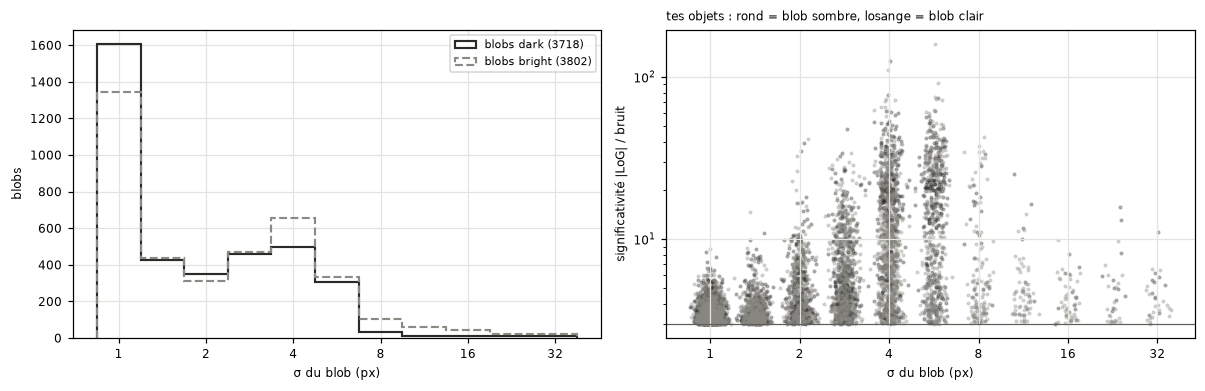

In [47]:
def plot_blobs():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    centers = np.array(GRIDS[ss.LOG_GRID])
    edges = np.sqrt(centers[:-1] * centers[1:])
    bins = np.concatenate([[centers[0] / 1.19], edges, [centers[-1] * 1.19]])
    for polarity, color, style in (("dark", "#2b2a27", "-"), ("bright", "#8a8983", "--")):
        sel = blobs[blobs["polarity"] == polarity]
        axes[0].hist(sel["sigma"], bins=bins, histtype="step", lw=1.4, color=color, linestyle=style,
                     label=f"blobs {polarity} ({len(sel)})")
        axes[1].scatter(sel["sigma"] * np.exp(np.random.default_rng(0).normal(0, 0.05, len(sel))),
                        sel["significance"], s=3, color=color, alpha=0.3, label=f"blobs {polarity}")
    if "polarity" in blob_table:
        for o in blob_table.dropna(subset=["polarity"]).itertuples():
            axes[1].scatter(o.blob_sigma, o.blob_significance, s=40, color=CLASSES[o.cls], edgecolor="white",
                            marker="o" if o.polarity == "dark" else "D", zorder=3)
            axes[1].annotate(o.id, (o.blob_sigma, o.blob_significance), fontsize=6, xytext=(3, 3),
                             textcoords="offset points")
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xticks(GRIDS["octave"], [f"{s:g}" for s in GRIDS["octave"]])
        ax.minorticks_off()
        ax.set_xlabel("σ du blob (px)")
    axes[0].set_ylabel("blobs"), axes[0].legend(fontsize=7)
    axes[1].set_yscale("log"), axes[1].set_ylabel("significativité |LoG| / bruit")
    axes[1].axhline(ss.SIGNIFICANCE_K, color="#5f5e58", lw=0.8)
    axes[1].set_title("tes objets : rond = blob sombre, losange = blob clair", loc="left", fontsize=8)
    fig.tight_layout()
    plt.show()


plot_blobs()


#### Concepts et transformations
- **Histogramme des σ des blobs**
  - *Simple :* combien de blobs à chaque taille, sombres et clairs séparés.
  - *Théorie / maths :* une classe d'histogramme par σ de la grille (bornes aux moyennes géométriques) ; un excès à la première bande = bruit fin (le bruit pixel à pixel forme des micro-taches).
- **Significativité contre σ**
  - *Simple :* chaque point = un blob : sa taille en x, sa force en y. Tes objets sont mis en couleur.
  - *Théorie / maths :* nuage (échelle, $Z$) en log-log ; un léger décalage aléatoire en x (*jitter*) évite que les points d'un même σ se superposent ; ligne = seuil $Z = 3$.
- **Séparer objets et bruit**
  - *Simple :* si tes objets sont tous en haut du nuage, un seuil plus haut garderait les cellules et enlèverait le fond.
  - *Théorie / maths :* choix d'un seuil de détection = compromis entre faux positifs et faux négatifs (courbe précision / rappel).


## 10 — La Hessienne : forme et orientation
**Ce que c'est :** à chaque σ, la matrice des dérivées secondes σ²H = [[Hxx, Hxy], [Hxy, Hyy]] décrit la courbure
locale dans toutes les directions. Ses deux valeurs propres :
- **λ1** (la plus grande en valeur absolue) = courbure la plus forte, **dans la largeur** de l'objet ;
  λ1 > 0 = structure **sombre**, λ1 < 0 = **claire** ;
- **λ2** = courbure dans l'autre direction (le long de l'objet).

Cartes (par pixel, au σ où σ²|λ1| est maximal) : `4 hessian sigma`, `4 hessian -lambda1` (affiché en −λ1 : bleu
sombre, rouge clair, comme l'amplitude), `4 hessian anisotropy` = 1 − |λ2|/|λ1| (0 = rond, 1 = bâtonnet),
`4 hessian long axis` (traits = axe long, jaune sombre / violet clair). Les ellipses sur tes objets : petit axe
= ta largeur, rapport des axes = √(|λ1|/|λ2|) plafonné à 5 (visuel, pas une mesure).

**σ attendu :** pour un bâtonnet de largeur w, la courbure dans la largeur est maximale à σ = w/2 (et non
w/(2√2) comme pour un disque).

**Questions :** les traits suivent-ils l'axe des bâtonnets ? Ta ligne tracée est-elle perpendiculaire au trait
(colonne `angle_to_line`, 0° = parfaitement en travers) ? Anisotropie : différente entre classes ? Le signe de λ1
au centre suit-il la classe comme le signe de B ? Que deviennent les halos (anneau clair = λ1 < 0 tout autour) ?


#### Concepts et transformations
- **Matrice hessienne**
  - *Simple :* le tableau des courbures de l'intensité : dans quelle direction ça se creuse le plus, et de combien.
  - *Théorie / maths :* $H = \begin{pmatrix} L_{xx} & L_{xy} \\ L_{xy} & L_{yy} \end{pmatrix}$, dérivées secondes de $L = G_\sigma * I$, normalisée par $\sigma^2$ ; $\mathrm{tr}\,H = \nabla^2 L$ (le LoG est sa trace).
- **Valeurs propres λ1, λ2**
  - *Simple :* les deux courbures principales, la plus forte et la plus faible.
  - *Théorie / maths :* $\lambda_\pm = \frac{L_{xx}+L_{yy}}{2} \pm \sqrt{\left(\frac{L_{xx}-L_{yy}}{2}\right)^2 + L_{xy}^2}$, triées par $|\lambda|$ ; $\lambda_1 > 0$ = minimum d'intensité dans cette direction (vallée sombre).
- **Vecteurs propres et orientation**
  - *Simple :* la direction de la courbure la plus forte traverse le bâtonnet ; l'axe long est perpendiculaire.
  - *Théorie / maths :* $\theta = \tfrac12 \operatorname{atan2}(2L_{xy}, L_{xx} - L_{yy})$ ; axe long = $\theta_{\lambda_1} + 90°$, en degrés depuis l'axe x, sens horaire à l'écran (y vers le bas), défini modulo 180°.
- **Anisotropie**
  - *Simple :* 0 = rond (même courbure partout), 1 = allongé (courbe dans un seul sens).
  - *Théorie / maths :* $A = 1 - |\lambda_2| / |\lambda_1| \in [0, 1]$ ; disque : $\lambda_1 \approx \lambda_2$ ; crête / bâtonnet : $|\lambda_2| \ll |\lambda_1|$ (mesures de type Frangi).
- **Sélection d'échelle**
  - *Simple :* pour chaque pixel, on garde le σ où la courbure principale est la plus forte.
  - *Théorie / maths :* $\sigma^* = \arg\max_\sigma \sigma^2|\lambda_1(\sigma)|$ ; bâtonnet de largeur $w$ : $\sigma^* = w/2$ (profil 1D, $u\,e^{-u^2/2}$ maximal pour $u = w/2\sigma = 1$).


In [48]:
if "log_hessian" not in h:
    raise RuntimeError("Le kernel utilise l'ancienne version du script : redémarre le kernel et relance la cellule 0.")
LH = h["log_hessian"]
HM = LH["maps"]
HESS_MAP = "4 hessian anisotropy"     # or "4 hessian -lambda1", "4 hessian sigma"
show("2 frame", HESS_MAP)
layer(HESS_MAP).opacity = 0.5
layer("4 hessian long axis").visible = True
layer("4 LoG blobs").visible = False


def object_ellipses():
    """Ellipse per object: minor axis = drawn width, axis ratio sqrt(|lambda1| / |lambda2|) capped at 5."""
    shapes, colors = [], []
    for o in objects.itertuples():
        y, x = int(round(o.y)), int(round(o.x))
        l1, l2, phi = HM["lambda1"][y, x], HM["lambda2"][y, x], np.radians(HM["orientation"][y, x])
        if not np.isfinite(l1):
            continue
        b = o.width / 2
        a = b * min(np.sqrt(abs(l1) / max(abs(l2), 1e-6)), 5)
        e_long, e_across = np.array([np.sin(phi), np.cos(phi)]), np.array([np.cos(phi), -np.sin(phi)])
        c0 = np.array([o.y, o.x])
        shapes.append([c0 - a * e_long - b * e_across, c0 + a * e_long - b * e_across,
                       c0 + a * e_long + b * e_across, c0 - a * e_long + b * e_across])
        colors.append(CLASSES[o.cls])
    if "hessian ellipses" in viewer.layers:
        viewer.layers.remove("hessian ellipses")
    if shapes:
        viewer.add_shapes(shapes, shape_type="ellipse", name="hessian ellipses", edge_color=colors,
                          face_color="transparent", edge_width=1)


object_ellipses()
# zoom_to(y, x, size=80)


#### Concepts et transformations
- **Superposition carte + traits + ellipses**
  - *Simple :* on voit en même temps l'allongement (couleur), la direction (traits) et la forme estimée de tes objets (ellipses).
  - *Théorie / maths :* calque Vectors (segments centrés, longueur 2σ, un tous les 6 px où A ≥ 0,5) et calque Shapes de type ellipse (4 coins de la boîte englobante orientée).
- **Ellipse depuis la Hessienne**
  - *Simple :* une ellipse plus allongée quand les deux courbures sont très différentes.
  - *Théorie / maths :* rapport des axes $\sqrt{|\lambda_1|/|\lambda_2|}$ : indicatif seulement, car au σ choisi les courbures mélangent la taille de l'objet et celle du filtre ($\lambda \propto 1/(s^2 + \sigma^2)$ pour une gaussienne d'écart-type $s$).


In [49]:
def hessian_features():
    rows = []
    for o in objects.itertuples():
        y, x = int(round(o.y)), int(round(o.x))
        line = np.degrees(np.arctan2(o.y2 - o.y1, o.x2 - o.x1))
        across = HM["orientation"][y, x] + 90            # direction of the strongest curvature
        rows.append(dict(cls=o.cls, id=o.id, width=round(o.width, 1), expected_sigma_rod=round(o.width / 2, 2),
                         sigma=HM["sigma"][y, x], lambda1=HM["lambda1"][y, x], lambda2=HM["lambda2"][y, x],
                         anisotropy=HM["anisotropy"][y, x], orientation=HM["orientation"][y, x],
                         angle_to_line=abs((line - across + 90) % 180 - 90), significance=HM["significance"][y, x]))
    return pd.DataFrame(rows).round(2)


hess_table = hessian_features()
if len(hess_table):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for cls, color in CLASSES.items():
        sel = hess_table[hess_table["cls"] == cls]
        axes[0].scatter(sel["lambda1"], sel["anisotropy"], color=color, s=30, edgecolor="white", label=cls)
        axes[1].scatter(sel["expected_sigma_rod"], sel["sigma"], color=color, s=30, edgecolor="white", label=cls)
        for o in sel.itertuples():
            axes[0].annotate(o.id, (o.lambda1, o.anisotropy), fontsize=6, xytext=(3, 3), textcoords="offset points")
    axes[0].axvline(0, color="#5f5e58", lw=0.8)
    axes[0].set_xlabel("λ1 au centre (> 0 sombre, < 0 clair)"), axes[0].set_ylabel("anisotropie (0 rond … 1 bâtonnet)")
    lim = (1, 2 ** ss.LOG_MAX)
    axes[1].plot(lim, lim, color="#8a8983", lw=1)
    axes[1].set_xscale("log", base=2), axes[1].set_yscale("log", base=2)
    axes[1].set_xlim(lim), axes[1].set_ylim(lim)
    axes[1].set_xlabel("σ attendu bâtonnet = largeur / 2 (px)"), axes[1].set_ylabel("σ Hessienne au centre (px)")
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    plt.show()
hess_table


""


#### Concepts et transformations
- **λ1 contre anisotropie**
  - *Simple :* en x le signe (sombre / clair), en y l'allongement : deux informations indépendantes sur le même graphe.
  - *Théorie / maths :* espace de descripteurs 2D ; deux classes séparées par une droite verticale = séparation par le signe seul ; séparées horizontalement = par la forme.
- **Angle avec ta ligne**
  - *Simple :* 0° : ta ligne traverse exactement l'objet dans la direction de la plus forte courbure ; 90° : elle est le long de l'objet.
  - *Théorie / maths :* $\Delta = |((\alpha_{ligne} - \theta_{\lambda_1}) + 90) \bmod 180 - 90| \in [0°, 90°]$ (différence d'angles d'axes, définis modulo 180°). Vérifie l'orientation sans vérité terrain supplémentaire.
- **σ attendu contre σ mesuré**
  - *Simple :* sur la diagonale, la Hessienne trouve la taille prévue par ta largeur.
  - *Théorie / maths :* modèle bâtonnet $\sigma^* = w/2$ ; un point au-dessus = structure plus large que la ligne tracée (halo inclus), au-dessous = plus fine.


## 11 — Synthèse
Tableau par objet (largeur, σ attendu, mesures au centre dans les deux grilles, gain de contraste du dernier jeu
de poids mesuré, blob LoG et Hessienne au centre si les étapes 9–10 ont été exécutées), puis résumé par classe (médiane, min, max). Enregistré en CSV (jamais écrasé).

À compléter toi-même ci-dessous :
1. Tableau par classe : σ caractéristique, signe, amplitude, passage par 0, au centre et au bord.
2. La ou les grandeurs qui séparent le mieux les classes, et les cas où elles échouent.
3. La grille retenue (octave / demi-octave) et l'étendue nécessaire.
4. Le meilleur jeu de poids, avec ses artefacts.

#### Concepts et transformations
- **Séparabilité**
  - *Simple :* une mesure sépare les classes si leurs valeurs ne se chevauchent pas.
  - *Théorie / maths :* classes séparables par un seuil sur une variable : intervalles [min, max] disjoints ; recouvrement = erreurs de classement inévitables avec cette seule variable.
- **Résumé par classe**
  - *Simple :* médiane, min et max de chaque mesure.
  - *Théorie / maths :* statistiques d'ordre (médiane, extrêmes) : décrivent position et étendue sans supposer de loi.


In [ ]:
summary = center_features("half_octave").merge(
    center_features("octave")[["id", "sigma_peak", "amplitude", "sigma_sign_change"]], on="id",
    suffixes=("", "_octave"))
if history:
    summary = summary.merge(history[-1]["table"][["id", "gain"]], on="id", how="left")
for extra, cols in (("blob_table", ["id", "polarity", "blob_sigma", "blob_significance"]),
                   ("hess_table", ["id", "lambda1", "anisotropy", "angle_to_line"])):
    if extra in globals() and len(globals()[extra]):
        summary = summary.merge(globals()[extra][[c for c in cols if c in globals()[extra]]], on="id", how="left")
if summary.empty:
    raise SystemExit("aucun objet : trace ou recharge les lignes (étape 1) avant la synthèse")
path = free_path(ss.DATA_DIR / f"{PREFIX}_summary.csv")
summary.to_csv(path, index=False)
print("enregistré :", path)
numeric = summary.select_dtypes("number").assign(cls=summary["cls"])
display(summary)
numeric.groupby("cls").agg(["median", "min", "max"]).round(2).T

SystemExit: aucun objet : trace ou recharge les lignes (étape 1) avant la synthèse

/Users/juwul/Desktop/Internship/.venv/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


: 

#### Concepts et transformations
- **Jointure de tables**
  - *Simple :* on assemble les mesures des deux grilles et le gain du sharpening objet par objet.
  - *Théorie / maths :* `merge` sur la clé `id` (jointure relationnelle, à gauche pour le gain qui peut manquer).
- **Export CSV**
  - *Simple :* le tableau est enregistré sans écraser l'ancien.
  - *Théorie / maths :* trace reproductible des résultats d'une session.


### Mes conclusions

- **in_focus :**
- **out_of_focus :**
- **ambigu :**
- **Grandeur(s) qui séparent :**
- **Grille :**
- **Poids :**

#### Concepts et transformations
- **Règle de décision**
  - *Simple :* une phrase du type « si B < 0 au centre, alors in focus ».
  - *Théorie / maths :* classifieur à seuil sur une variable : $\hat y = \text{in}$ si $A < 0$, $\text{out}$ sinon ; seuil $\theta = 0$.
- **Exactitude**
  - *Simple :* la part des objets bien classés.
  - *Théorie / maths :* $\text{exactitude} = \frac{\text{bien classés}}{\text{total}}$ ; matrice de confusion (vrais / faux positifs et négatifs) par classe.


### Exemple de conclusion (frame 207, vidéo 0003)
*Rédigé à partir de `0003_4_seg0_frame207_summary.csv` et des sorties de ce notebook (2026-11-11). Les points 6 et 7 sont à compléter d'après les graphiques.*

**Échantillon.** 6 in focus, 13 out of focus et 11 ambigus, classés visuellement sur l'image d'entrée. Tous les objets sont significatifs au centre (significativité ≥ 13,9).

**1. Le signe sépare les deux classes dans cet échantillon.**
- On regarde l'amplitude au pic, au centre de l'objet (demi-octave) :
  - **in focus : toujours négative**, de −4,2 à −7,6 % (6/6) ;
  - **out of focus : toujours positive**, de +2,6 à +6,5 % (13/13).
- La règle « B < 0 au centre = in focus, B > 0 = out of focus » classe donc correctement les **19 objets sur 19**.
- La grille octave donne le même résultat (−3,3 à −6,0 contre +2,1 à +4,7).
- **À noter :** à l'étape 1, j'avais vu des centres plus clairs que le fond. Le signe de B ne compare pas au fond global, mais au **voisinage immédiat à l'échelle du pic**. Le centre d'un in focus est donc plus sombre que son entourage proche (le halo), même s'il paraît clair par rapport au fond.

**2. Le σ du pic ne sépare pas les classes : il mesure la taille.**
- σ du pic : in focus de 2,9 à 5,3 (médiane 3,5), out of focus de 2,9 à 6,6 (médiane 3,9). Les deux intervalles se recouvrent presque entièrement.
- Les largeurs se recouvrent aussi : 7,0–15,8 px contre 6,9–17,3 px.
- Le σ mesuré suit la valeur attendue largeur / 2√2 dans les deux classes (par exemple in2 : 2,85 attendu, 3,29 mesuré ; out12 : 6,10 attendu, 6,60 mesuré).
- C'est ce qui explique que les couleurs de la carte `sigma peak` ne séparaient rien : elles codent la taille de l'objet, pas sa mise au point.

**3. Indices secondaires, qui ne suffisent pas seuls.**
- **Significativité :** plus élevée pour les in focus (médiane 33, contre 20), mais les intervalles se chevauchent (in focus ≥ 24 ; out2 atteint 35,7).
- **Changement de signe au centre :** jamais pour les in focus (0/6), rare pour les out of focus (2/13 : out3 à σ 8,0, out9 à σ 18,7), fréquent pour les ambigus (7/11).

**4. Les ambigus**
- Ils sont nettement plus gros (largeur 19–60 px, médiane 33) et ont un σ du pic plus grand (médiane 5,1, jusqu'à 11,8). Leur σ mesuré reste bien en dessous du σ attendu (5,1 contre 11,7 en médiane) : la structure dominante est plus petite que l'objet entier. C'est cohérent avec des **amas** de plusieurs cellules.
- Par le signe, 10 sur 11 ressemblent à des out of focus (B > 0). Seul **amb9** est négatif (−5,1), comme un in focus.

**5. Grille**
- Octave et demi-octave donnent le même σ du pic à environ 0,1–0,4 px près, et le même signe pour tous les objets.
- Pour le critère du signe, **l'octave suffit**. L'étendue jusqu'à σ 32 sert surtout aux ambigus et aux amas (amb8 : σ 11,8). Aucun objet n'a son pic sur la première ou la dernière bande.

**6. Sharpening**
- Jeu testé : bandes 1–1,41, 2,83–4, 8–11,3 et 22,6–32 réglées à ~4 (poids 1, 4,2, 1, 1, 3,9, 1, 1, 3,9, 1, 1, 4,1).
- Le gain de contraste est **quasi identique pour toutes les classes** (médianes 1,96 / 1,97 / 1,93 ; de 1,87 à 2,23 objet par objet).
- Ce jeu de poids **amplifie tout de la même façon, sans séparer**. Ce n'est d'ailleurs pas nécessaire : le signe sépare déjà les deux classes sans sharpening.
- *(À compléter d'après tes graphiques : artefacts, bruit de fond.)*

**7. Heightmap** — *à compléter d'après tes observations* (forme des collines et des cuvettes par classe).

**Limites**
- Une seule frame, et seulement 6 in focus.
- Une seule mesure au centre : le signe peut dépendre du pixel choisi, surtout sur les petits objets.
- La référence est ma propre classification visuelle.

**Prochaines étapes**
- Tester la règle du signe sur d'autres frames de 0003 et sur Expo3 frame 688.
- Mesurer le signe moyen sur une petite zone centrale plutôt que sur un seul pixel.
- Décider comment traiter les amas (ambigus).

#### Concepts et transformations
- **19/19 sur un petit échantillon**
  - *Simple :* aucune erreur sur 19 objets, mais 19 c'est peu.
  - *Théorie / maths :* « règle de trois » : avec 0 erreur sur $n$, le taux d'erreur réel est $\le 3/n$ à 95 % de confiance, soit $\le 16\,\%$ pour $n=19$. D'où l'intérêt de tester d'autres frames.
- **Généralisation**
  - *Simple :* une règle trouvée sur une frame doit marcher sur d'autres frames et d'autres vidéos.
  - *Théorie / maths :* validation sur des données non vues (hors échantillon) ; sinon risque de surajustement à une seule image.
- **Taille vs mise au point**
  - *Simple :* σ mesure la taille, le signe mesure l'état de mise au point : ce sont deux informations indépendantes.
  - *Théorie / maths :* $\sigma^*$ corrélé à la largeur ($\sigma^* \approx w/2\sqrt2$), le signe de $A$ lié à la polarité du contraste (défocalisation).
- **Mesure sur une zone**
  - *Simple :* lire le signe sur quelques pixels autour du centre plutôt qu'un seul.
  - *Théorie / maths :* moyenne locale $\bar A$ sur un disque central : réduit la variance de la mesure en $1/\sqrt{N}$.
